In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, en k€) se adjunta. El coste planificado de cada actividad se reparte uniformemente a lo largo de su duración.

In [3]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 2       , 20 ),
    ('B'     , '---'      , 2       , 60 ),
    ('C'     , 'B'        , 2       , 60 ),
    ('D'     , 'B'        , 1       , 10 ),
    ('E'     , 'C,D'      , 4       , 40 ),
    ('F'     , 'E'        , 1       , 30 ),
    ('G'     , 'E'        , 3       , 60 ),
    ('H'     , 'A,F'      , 4       , 50 ),
    ('I'     , 'G,H'      , 5       , 10 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,2,20
B,---,2,60
C,B,2,60
D,B,1,10
E,"C,D",4,40
F,E,1,30
G,E,3,60
H,"A,F",4,50
I,"G,H",5,10


El proyecto corresponde a el lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [4]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
    'I': 'Pruebas de integración',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización
I,Pruebas de integración


Se han realizado tres puntos de control, al final de las semanas 5, 10 y 14. En cada uno se anotó, para cada actividad, las semanas trabajadas hasta ese momento, el coste real incurrido (k€) y el porcentaje realizado.

In [5]:
#| tbl-cap: "Punto de control 1 (final de la semana 5)"
#| label: tbl-seguimiento1
seguimiento_1 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 2              , 24, 100      ),
    ('B'     , 3              , 60, 100      ),
    ('C'     , 2              , 48, 67       ),
    ('D'     , 2              , 12, 100      ),
    ('E'     , 0              , 0 , 0        ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
    ('I'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_1

,actual_duration,AC,performed
activity,,,
A,2,24,100
B,3,60,100
C,2,48,67
D,2,12,100
E,0,0,0
F,0,0,0
G,0,0,0
H,0,0,0
I,0,0,0


In [6]:
#| tbl-cap: "Punto de control 2 (final de la semana 10)"
#| label: tbl-seguimiento2
seguimiento_2 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 2              , 24, 100      ),
    ('B'     , 3              , 60, 100      ),
    ('C'     , 3              , 72, 100      ),
    ('D'     , 2              , 12, 100      ),
    ('E'     , 4              , 29, 67       ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
    ('I'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_2

,actual_duration,AC,performed
activity,,,
A,2,24,100
B,3,60,100
C,3,72,100
D,2,12,100
E,4,29,67
F,0,0,0
G,0,0,0
H,0,0,0
I,0,0,0


In [7]:
#| tbl-cap: "Punto de control 3 (final de la semana 14)"
#| label: tbl-seguimiento3
seguimiento_3 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 2              , 24, 100      ),
    ('B'     , 3              , 60, 100      ),
    ('C'     , 3              , 72, 100      ),
    ('D'     , 2              , 12, 100      ),
    ('E'     , 6              , 44, 100      ),
    ('F'     , 1              , 45, 100      ),
    ('G'     , 2              , 30, 50       ),
    ('H'     , 1              , 7 , 12       ),
    ('I'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_3

,actual_duration,AC,performed
activity,,,
A,2,24,100
B,3,60,100
C,3,72,100
D,2,12,100
E,6,44,100
F,1,45,100
G,2,30,50
H,1,7,12
I,0,0,0


In [8]:
pregunta_1 = "1. Calcule PV, EV y AC en cada punto de control.  "
pregunta_2 = "2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  "
pregunta_3 = "3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  "
pregunta_4 = "4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule PV, EV y AC en cada punto de control.  

2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  

3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  

4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  

# Resolución

In [9]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])

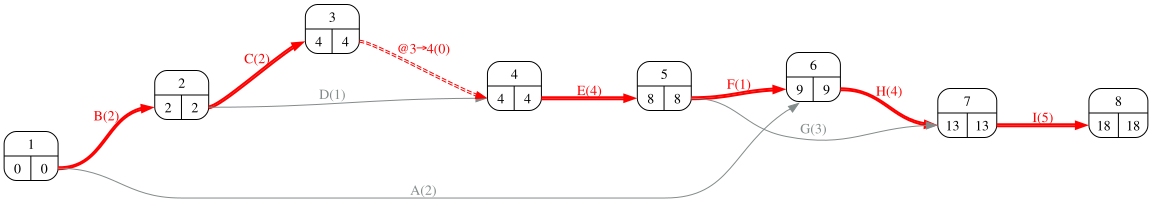

In [10]:
#| fig-cap: "Grafo PERT de la planificación"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

## Apartado 1

In [11]:
display(Markdown(pregunta_1))

1. Calcule PV, EV y AC en cada punto de control.  

In [12]:
seguimientos = {5: seguimiento_1, 10: seguimiento_2, 14: seguimiento_3}
filas = {}
curvas = {}
for semana, seguimiento in seguimientos.items():
    datos_vg = pd.concat([datos_proyecto, seguimiento], axis=1)
    gantts = EarnedValue(proyecto.copy()).calcula_gantts(datos_vg, planned_durations_label='duration',
                                                          actual_durations_label='actual_duration', PV_label='BAC',
                                                          AC_label='AC', percentage_complete_label='performed', tikz=False)
    PV = float(gantts['acumulados'].loc[semana, 'PV'])
    EV = float((datos_vg['BAC'] * datos_vg['performed'] / 100).sum())
    AC = float(datos_vg['AC'].sum())
    filas[semana] = {'PV': PV, 'EV': EV, 'AC': AC}
indicadores = pd.DataFrame(filas).T
indicadores.index.name = 'semana'
indicadores.round(1)

,PV,EV,AC
semana,,,
5,160.0,130.2,144.0
10,272.5,176.8,197.0
14,332.0,256.0,294.0


## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  

In [14]:
indicadores['CV'] = indicadores['EV'] - indicadores['AC']
indicadores['SV'] = indicadores['EV'] - indicadores['PV']
indicadores['CPI'] = indicadores['EV'] / indicadores['AC']
indicadores['SPI'] = indicadores['EV'] / indicadores['PV']
indicadores.round(3)

,PV,EV,AC,CV,SV,CPI,SPI
semana,,,,,,,
5,160.0,130.2,144.0,-13.8,-29.8,0.904,0.814
10,272.5,176.8,197.0,-20.2,-95.7,0.897,0.649
14,332.0,256.0,294.0,-38.0,-76.0,0.871,0.771


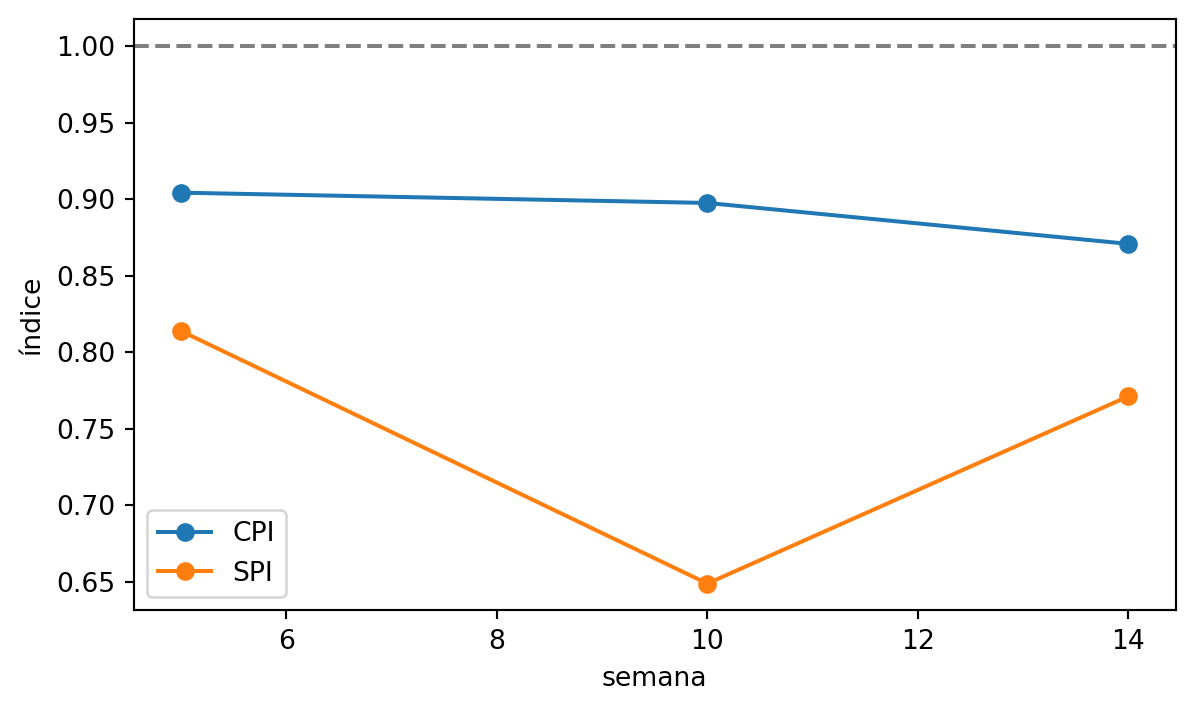

In [15]:
#| fig-cap: "Evolución de CPI y SPI"
#| label: fig-evolucion
ax = indicadores[['CPI', 'SPI']].plot(marker='o', figsize=(7, 4))
ax.axhline(1, color='grey', linestyle='--'); ax.set_ylabel('índice');

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  

In [17]:
indicadores['EAC'] = BAC_total / indicadores['CPI']
indicadores['VAC'] = BAC_total - indicadores['EAC']
indicadores[['CPI', 'EAC', 'VAC']].round({'CPI': 3, 'EAC': 1, 'VAC': 1})

,CPI,EAC,VAC
semana,,,
5,0.904,376.0,-36.0
10,0.897,378.8,-38.8
14,0.871,390.5,-50.5


## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  

In [19]:
cpi = indicadores['CPI']; spi = indicadores['SPI']
tend_c = 'mejora' if cpi.iloc[-1] > cpi.iloc[0] else 'empeora'
tend_s = 'mejora' if spi.iloc[-1] > spi.iloc[0] else 'empeora'
Markdown(f'''Entre el primer y el último punto de control el CPI {tend_c} ({cpi.iloc[0]:.2f} → {cpi.iloc[-1]:.2f}) y el SPI {tend_s} ({spi.iloc[0]:.2f} → {spi.iloc[-1]:.2f}). La previsión de coste final pasa de {indicadores["EAC"].iloc[0]:.0f} a {indicadores["EAC"].iloc[-1]:.0f} k€ frente a un presupuesto de {BAC_total:.0f}. Conviene recordar que el SPI tiende a 1 al final del proyecto aunque haya retraso, así que su mejora en los últimos puntos puede ser aparente; para el plazo es preferible la programación ganada. Tras el último control procede revisar las actividades pendientes: acelerar las críticas (si el sobrecoste compensa la penalización o los costes indirectos) y revisar las causas del sobrecoste en las ya ejecutadas para que no se repitan.''')

Entre el primer y el último punto de control el CPI empeora (0.90 → 0.87) y el SPI empeora (0.81 → 0.77). La previsión de coste final pasa de 376 a 390 k€ frente a un presupuesto de 340. Conviene recordar que el SPI tiende a 1 al final del proyecto aunque haya retraso, así que su mejora en los últimos puntos puede ser aparente; para el plazo es preferible la programación ganada. Tras el último control procede revisar las actividades pendientes: acelerar las críticas (si el sobrecoste compensa la penalización o los costes indirectos) y revisar las causas del sobrecoste en las ya ejecutadas para que no se repitan.